# UPGMA Trees

Reconstruct an ultrametric tree from an artificial distance matrix and compare its implied pair distances with the input.

Average linkage weights clusters by their number of leaves. Under an ultrametric model, every leaf is the same distance from the root. Linkage heights are pair distances; phylogenetic node heights are half those values.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import squareform

## Worked example

Run the example from top to bottom. The printed check and figure use the same observations.

Cophenetic correlation 1.000 | maximum distance error 0.000


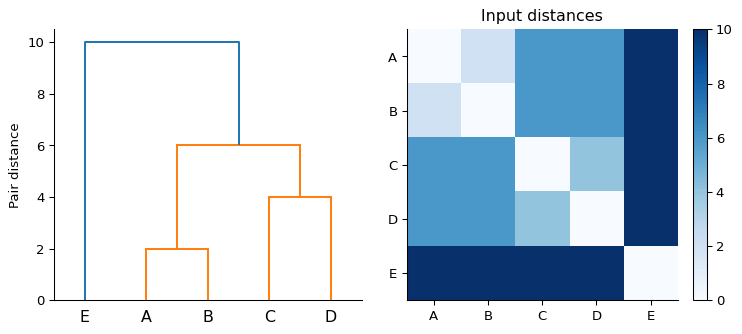

In [2]:
D = np.array(
    [[0, 2, 6, 6, 10], [2, 0, 6, 6, 10], [6, 6, 0, 4, 10], [6, 6, 4, 0, 10], [10, 10, 10, 10, 0]],
    float,
)
dist = squareform(D)
Z = linkage(dist, method="average")
corr, implied = cophenet(Z, dist)
print(f"Cophenetic correlation {corr:.3f} | maximum distance error {max(abs(implied-dist)):.3f}")
assert np.allclose(implied, dist)
fig, (a, b) = plt.subplots(1, 2, figsize=(7.7, 3.4), constrained_layout=True)
dendrogram(Z, labels=list("ABCDE"), ax=a)
a.set_ylabel("Pair distance")
im = b.imshow(D, cmap="Blues")
b.set(
    title="Input distances",
    xticks=range(5),
    xticklabels=list("ABCDE"),
    yticks=range(5),
    yticklabels=list("ABCDE"),
)
fig.colorbar(im, ax=b)
plt.show()

## Interpreting the result

Exact agreement is expected for this constructed ultrametric matrix. A rate change on a single lineage can break that property.

## Exercise

Change one distance symmetrically and measure the cophenetic error again.

## References

[SciPy, average linkage and UPGMA](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html)